# Tarea 10 — Comparación experimental de métodos de selección de características

> Uriel Aguilar Mauricio

## Importaciones y parámetros

Se reúnen todas las importaciones en **una sola celda**, como solicitaste. No se instalan paquetes. Usamos una misma semilla y partición para asegurar una comparación justa. `PyGAD` debe estar ya disponible.

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pygad
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.base import clone

### Configuración del experimento

`K` es el máximo de características usado por Información Mutua y RFE; LASSO y el algoritmo genético pueden escoger otros tamaños y se reportan tal cual. Cambiar hiperparámetros modifica el experimento y debe declararse en el reporte.

In [56]:
RUTA_PC2 = "../data/raw/PC2.csv" 
SEMILLA = 42
PROPORCION_PRUEBA = 0.30
K = 10
C_L1 = 1.0
GENERACIONES_AG = 12
POBLACION_AG = 12
PENALIZACION_TAMANO = 0.02

## Exploración inicial de PC2 (EDA)

La consigna exige: número de instancias, predictores, variable objetivo, estadísticas y distribución de clases, así como identificación de métricas McCabe, Halstead y LOC. Primero inspeccionamos el archivo **sin alterar sus datos**.

In [4]:
ruta = Path(RUTA_PC2).expanduser()

In [6]:
df_original = pd.read_csv(ruta, sep=None, engine="python")
display(df_original.head(8))

,id,LOC_BLANK,BRANCH_COUNT,CALL_PAIRS,LOC_CODE_AND_COMMENT,LOC_COMMENTS,CONDITION_COUNT,CYCLOMATIC_COMPLEXITY,CYCLOMATIC_DENSITY,DECISION_COUNT,...,NORMALIZED_CYLOMATIC_COMPLEXITY,NUM_OPERANDS,NUM_OPERATORS,NUM_UNIQUE_OPERANDS,NUM_UNIQUE_OPERATORS,NUMBER_OF_LINES,PATHOLOGICAL_COMPLEXITY,PERCENT_COMMENTS,LOC_TOTAL,Defective
0,1,0,7,1,14,0,12,4,0.24,6,...,0.20,37,54,9,14,20,1,82.35,17,N
1,2,0,7,2,14,0,12,4,0.24,6,...,0.20,39,56,10,14,20,1,82.35,17,N
2,3,0,7,0,4,0,12,4,0.80,6,...,0.50,6,11,3,7,8,1,80.00,5,N
3,4,0,3,0,1,0,4,2,1.00,2,...,0.50,2,5,2,5,4,1,50.00,2,N
4,5,0,3,0,1,14,4,2,1.00,2,...,0.11,2,5,2,5,18,1,93.75,2,N
5,6,0,1,0,1,0,0,1,0.50,0,...,0.20,2,3,2,3,5,1,50.00,2,N
6,7,0,3,1,5,0,4,2,0.29,2,...,0.20,12,14,4,9,10,1,71.43,7,N
7,8,0,3,1,5,0,4,2,0.29,2,...,0.18,14,16,5,9,11,1,71.43,7,N


In [7]:
print("Instancias y columnas:", df_original.shape)
print("Columnas originales:", df_original.columns.tolist())

Instancias y columnas: (5589, 42)
Columnas originales: ['id', 'LOC_BLANK', 'BRANCH_COUNT', 'CALL_PAIRS', 'LOC_CODE_AND_COMMENT', 'LOC_COMMENTS', 'CONDITION_COUNT', 'CYCLOMATIC_COMPLEXITY', 'CYCLOMATIC_DENSITY', 'DECISION_COUNT', 'DECISION_DENSITY', 'DESIGN_COMPLEXITY', 'DESIGN_DENSITY', 'EDGE_COUNT', 'ESSENTIAL_COMPLEXITY', 'ESSENTIAL_DENSITY', 'LOC_EXECUTABLE', 'PARAMETER_COUNT', 'GLOBAL_DATA_COMPLEXITY', 'GLOBAL_DATA_DENSITY', 'HALSTEAD_CONTENT', 'HALSTEAD_DIFFICULTY', 'HALSTEAD_EFFORT', 'HALSTEAD_ERROR_EST', 'HALSTEAD_LENGTH', 'HALSTEAD_LEVEL', 'HALSTEAD_PROG_TIME', 'HALSTEAD_VOLUME', 'MAINTENANCE_SEVERITY', 'MODIFIED_CONDITION_COUNT', 'MULTIPLE_CONDITION_COUNT', 'NODE_COUNT', 'NORMALIZED_CYLOMATIC_COMPLEXITY', 'NUM_OPERANDS', 'NUM_OPERATORS', 'NUM_UNIQUE_OPERANDS', 'NUM_UNIQUE_OPERATORS', 'NUMBER_OF_LINES', 'PATHOLOGICAL_COMPLEXITY', 'PERCENT_COMMENTS', 'LOC_TOTAL', 'Defective']


In [8]:
display(df_original.dtypes.rename("Tipo de dato").to_frame())

,Tipo de dato
id,int64
LOC_BLANK,int64
BRANCH_COUNT,int64
CALL_PAIRS,int64
LOC_CODE_AND_COMMENT,int64
LOC_COMMENTS,int64
CONDITION_COUNT,int64
CYCLOMATIC_COMPLEXITY,int64
CYCLOMATIC_DENSITY,float64
DECISION_COUNT,int64


In [9]:
display(df_original.isna().sum().rename("Nulos").to_frame())

,Nulos
id,0
LOC_BLANK,0
BRANCH_COUNT,0
CALL_PAIRS,0
LOC_CODE_AND_COMMENT,0
LOC_COMMENTS,0
CONDITION_COUNT,0
CYCLOMATIC_COMPLEXITY,0
CYCLOMATIC_DENSITY,0
DECISION_COUNT,0


In [10]:
display(df_original.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,5589.0,NaN,NaN,NaN,2795.0,1613.549658,1.0,1398.0,2795.0,4192.0,5589.0
LOC_BLANK,5589.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BRANCH_COUNT,5589.0,NaN,NaN,NaN,2.388621,5.680089,1.0,1.0,1.0,3.0,287.0
CALL_PAIRS,5589.0,NaN,NaN,NaN,1.321882,2.527017,0.0,0.0,1.0,2.0,74.0
LOC_CODE_AND_COMMENT,5589.0,NaN,NaN,NaN,3.688674,13.083444,0.0,0.0,1.0,3.0,558.0
LOC_COMMENTS,5589.0,NaN,NaN,NaN,1.109501,5.681901,0.0,0.0,0.0,0.0,111.0
CONDITION_COUNT,5589.0,NaN,NaN,NaN,2.59474,10.337392,0.0,0.0,0.0,4.0,570.0
CYCLOMATIC_COMPLEXITY,5589.0,NaN,NaN,NaN,1.719628,3.067531,1.0,1.0,1.0,2.0,144.0
CYCLOMATIC_DENSITY,5589.0,NaN,NaN,NaN,0.584573,0.302564,0.01,0.33,0.5,1.0,2.0
DECISION_COUNT,5589.0,NaN,NaN,NaN,1.22598,4.986876,0.0,0.0,0.0,2.0,284.0


### Identificación de la variable objetivo

En repositorios de NASA MDP aparecen variantes como `defects`, `Defective`, `bug` o `class`. Inspecciona la columna detectada antes de continuar; **la clase positiva será 1 = defectuoso**.

In [12]:
OBJETIVO = "Defective"
print("Variable objetivo:", OBJETIVO)
display(df_original[OBJETIVO].value_counts(dropna=False).rename("Frecuencia").to_frame())

Variable objetivo: Defective


,Frecuencia
Defective,
N,5566
Y,23


In [13]:
etiqueta_cruda = df_original[OBJETIVO]
print("Etiquetas presentes:", etiqueta_cruda.dropna().unique())

Etiquetas presentes: <StringArray>
['N', 'Y']
Length: 2, dtype: str


Se convierte la variable objetivo a 0/1 de manera explícita. Si tu archivo presenta códigos distintos, modifica el diccionario **según el significado de las etiquetas de tu versión**. No se asume que una etiqueta desconocida es negativa.

In [30]:
mapa_etiquetas = {"y": 1, "n": 0}

y = etiqueta_cruda.astype("string").str.strip().str.lower().map(mapa_etiquetas)

print("Registros sin etiqueta interpretable:", y.isna().sum())

Registros sin etiqueta interpretable: 0


In [32]:
print(etiqueta_cruda.value_counts(dropna=False))

Defective
N    5566
Y      23
Name: count, dtype: int64


In [34]:
y = y.astype(int)
print("0 = no defectuoso | 1 = defectuoso")
display(y.value_counts().sort_index().rename("Cantidad").to_frame())

0 = no defectuoso | 1 = defectuoso


,Cantidad
Defective,
0,5566
1,23


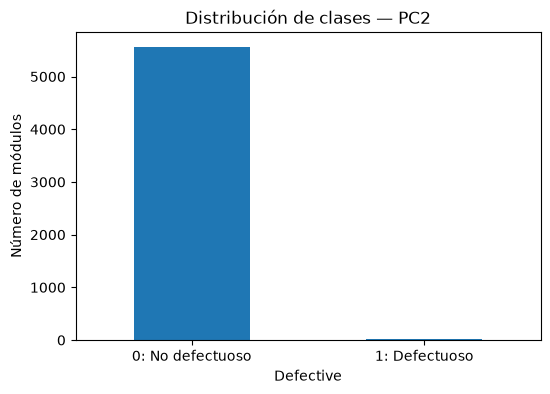

In [35]:
fig, ax = plt.subplots(figsize=(6, 4))
y.value_counts().sort_index().plot.bar(ax=ax)
ax.set_xticklabels(["0: No defectuoso", "1: Defectuoso"], rotation=0)
ax.set_title("Distribución de clases — PC2")
ax.set_ylabel("Número de módulos")
plt.show()

In [36]:
print("Porcentaje de módulos defectuosos:", round(100 * y.mean(), 3), "%")
print("Porcentaje de módulos no defectuosos:", round(100 * (1 - y.mean()), 3), "%")

Porcentaje de módulos defectuosos: 0.412 %
Porcentaje de módulos no defectuosos: 99.588 %


### Variables predictoras y familias de métricas

Las familias vistas en clase son: **McCabe** (complejidad de flujo/control: `v(g)`, `ev(g)`, `iv(g)`, ramas), **Halstead** (operadores, operandos, volumen y esfuerzo) y **LOC** (tamaño). El mapeo exacto depende de los encabezados del PC2 entregado; no se debe cambiar una métrica de familia solo por su correlación.

In [37]:
X_bruto = df_original.drop(columns=[OBJETIVO]).copy()
print("Total de columnas predictoras (antes de limpieza):", X_bruto.shape[1])

Total de columnas predictoras (antes de limpieza): 41


In [44]:
familias = pd.DataFrame([
    ["id", "Identificador"],
    ["LOC_BLANK", "Tamaño (LOC)"],
    ["BRANCH_COUNT", "McCabe"],
    ["CALL_PAIRS", "Estructurales"],
    ["LOC_CODE_AND_COMMENT", "Tamaño (LOC)"],
    ["LOC_COMMENTS", "Tamaño (LOC)"],
    ["CONDITION_COUNT", "Flujo de control"],
    ["CYCLOMATIC_COMPLEXITY", "McCabe"],
    ["CYCLOMATIC_DENSITY", "McCabe"],
    ["DECISION_COUNT", "Flujo de control"],
    ["DECISION_DENSITY", "Flujo de control"],
    ["DESIGN_COMPLEXITY", "McCabe"],
    ["DESIGN_DENSITY", "McCabe"],
    ["EDGE_COUNT", "Estructurales"],
    ["ESSENTIAL_COMPLEXITY", "McCabe"],
    ["ESSENTIAL_DENSITY", "McCabe"],
    ["LOC_EXECUTABLE", "Tamaño (LOC)"],
    ["PARAMETER_COUNT", "Estructurales"],
    ["GLOBAL_DATA_COMPLEXITY", "Complejidad de datos"],
    ["GLOBAL_DATA_DENSITY", "Complejidad de datos"],
    ["HALSTEAD_CONTENT", "Halstead"],
    ["HALSTEAD_DIFFICULTY", "Halstead"],
    ["HALSTEAD_EFFORT", "Halstead"],
    ["HALSTEAD_ERROR_EST", "Halstead"],
    ["HALSTEAD_LENGTH", "Halstead"],
    ["HALSTEAD_LEVEL", "Halstead"],
    ["HALSTEAD_PROG_TIME", "Halstead"],
    ["HALSTEAD_VOLUME", "Halstead"],
    ["MAINTENANCE_SEVERITY", "Mantenibilidad"],
    ["MODIFIED_CONDITION_COUNT", "Flujo de control"],
    ["MULTIPLE_CONDITION_COUNT", "Flujo de control"],
    ["NODE_COUNT", "Estructurales"],
    ["NORMALIZED_CYCLOMATIC_COMPLEXITY", "McCabe"],
    ["NUM_OPERANDS", "Halstead"],
    ["NUM_OPERATORS", "Halstead"],
    ["NUM_UNIQUE_OPERANDS", "Halstead"],
    ["NUM_UNIQUE_OPERATORS", "Halstead"],
    ["NUMBER_OF_LINES", "Tamaño (LOC)"],
    ["PATHOLOGICAL_COMPLEXITY", "McCabe"],
    ["PERCENT_COMMENTS", "Documentación"],
    ["LOC_TOTAL", "Tamaño (LOC)"]
], columns=["Variable", "Familia provisional"])

display(familias)

,Variable,Familia provisional
0,id,Identificador
1,LOC_BLANK,Tamaño (LOC)
2,BRANCH_COUNT,McCabe
3,CALL_PAIRS,Estructurales
4,LOC_CODE_AND_COMMENT,Tamaño (LOC)
5,LOC_COMMENTS,Tamaño (LOC)
6,CONDITION_COUNT,Flujo de control
7,CYCLOMATIC_COMPLEXITY,McCabe
8,CYCLOMATIC_DENSITY,McCabe
9,DECISION_COUNT,Flujo de control


In [45]:
display(
    familias["Familia provisional"]
    .value_counts()
    .rename("Variables")
    .to_frame()
)

,Variables
Familia provisional,
Halstead,12
McCabe,9
Tamaño (LOC),6
Flujo de control,5
Estructurales,4
Complejidad de datos,2
Identificador,1
Mantenibilidad,1
Documentación,1


### Calidad del dataset

Se revisan columnas no numéricas, constantes y valores ausentes. Las conversiones e imputaciones que aprenden de datos se harán **solo con entrenamiento** para evitar fuga de información.

In [47]:
X_numerico = X_bruto.apply(pd.to_numeric, errors="coerce")
display(X_numerico.isna().sum().rename("Valores faltantes / no numéricos").sort_values(ascending=False).to_frame())

,Valores faltantes / no numéricos
DECISION_DENSITY,4004
NODE_COUNT,0
HALSTEAD_ERROR_EST,0
HALSTEAD_LENGTH,0
HALSTEAD_LEVEL,0
HALSTEAD_PROG_TIME,0
HALSTEAD_VOLUME,0
MAINTENANCE_SEVERITY,0
MODIFIED_CONDITION_COUNT,0
MULTIPLE_CONDITION_COUNT,0


In [48]:
columnas_sin_datos = X_numerico.columns[X_numerico.isna().all()].tolist()
print("Columnas totalmente vacías/no numéricas:", columnas_sin_datos)

Columnas totalmente vacías/no numéricas: []


In [49]:
if columnas_sin_datos:
    raise ValueError("Hay predictores sin información numérica. Revisa estas columnas antes de continuar: " + str(columnas_sin_datos))

In [50]:
constantes = X_numerico.columns[X_numerico.nunique(dropna=True) <= 1].tolist()
print("Predictores constantes:", constantes)

Predictores constantes: ['LOC_BLANK', 'GLOBAL_DATA_COMPLEXITY', 'GLOBAL_DATA_DENSITY', 'PATHOLOGICAL_COMPLEXITY']


Una columna constante no aporta capacidad discriminativa y puede hacer más lento o confuso el análisis. Se retira **antes** de los cuatro métodos, por igual. Documentamos esta decisión.

In [51]:
X = X_numerico.drop(columns=constantes).copy()
columnas = X.columns.tolist()
print("Características compartidas por los cuatro métodos:", len(columnas))

Características compartidas por los cuatro métodos: 37


In [52]:
resumen_eda = pd.DataFrame({"Medida": ["Instancias", "Predictores originales", "Predictores comparados", "Defectuosos", "No defectuosos", "Prevalencia (%)"], "Valor": [len(X), X_bruto.shape[1], X.shape[1], int(y.sum()), int((y == 0).sum()), round(y.mean() * 100, 3)]})
display(resumen_eda)

,Medida,Valor
0,Instancias,5589.000
1,Predictores originales,41.000
2,Predictores comparados,37.000
3,Defectuosos,23.000
4,No defectuosos,5566.000
5,Prevalencia (%),0.412


## Diseño experimental y prevención de fuga de datos

**Partición única** estratificada 75/25. Los métodos seleccionan variables **solo con entrenamiento**; el conjunto de prueba permanece reservado hasta evaluar los clasificadores. La imputación y estandarización se ajustan en entrenamiento. Esto permite comparar los cuatro métodos sobre **las mismas entradas y la misma partición**.

La selección mediante Información Mutua usa los predictores imputados; RFE y L1 usan los estandarizados; PyGAD evalúa subconjuntos mediante validación cruzada interna. Los métodos no reciben diferente información, pero sí transformaciones apropiadas para sus algoritmos.

In [53]:
if y.nunique() != 2 or y.value_counts().min() < 4:
    raise ValueError("Se requieren ambas clases y al menos cuatro casos por clase para el experimento estratificado.")

In [57]:
X_ent, X_prueba, y_ent, y_prueba = train_test_split(X, y, test_size=PROPORCION_PRUEBA, random_state=SEMILLA, stratify=y)
print("Entrenamiento:", X_ent.shape, "| Prueba:", X_prueba.shape)

Entrenamiento: (3912, 37) | Prueba: (1677, 37)


In [58]:
distribucion = pd.DataFrame({"Entrenamiento": y_ent.value_counts(normalize=True).sort_index(), "Prueba": y_prueba.value_counts(normalize=True).sort_index()})
display(distribucion.rename(index={0: "No defectuoso", 1: "Defectuoso"}))

,Entrenamiento,Prueba
Defective,,
No defectuoso,0.99591,0.995826
Defectuoso,0.00409,0.004174


In [59]:
imputador = SimpleImputer(strategy="median", keep_empty_features=True)
X_ent_imp = imputador.fit_transform(X_ent)
X_prueba_imp = imputador.transform(X_prueba)
print("Imputación entrenada: mediana por variable")

Imputación entrenada: mediana por variable


In [60]:
escalador = StandardScaler()
X_ent_std = escalador.fit_transform(X_ent_imp)
X_prueba_std = escalador.transform(X_prueba_imp)
print("Estandarización: media y desviación de entrenamiento")

Estandarización: media y desviación de entrenamiento


In [61]:
display(pd.DataFrame(X_ent_std, columns=columnas).head())

,id,BRANCH_COUNT,CALL_PAIRS,LOC_CODE_AND_COMMENT,LOC_COMMENTS,CONDITION_COUNT,CYCLOMATIC_COMPLEXITY,CYCLOMATIC_DENSITY,DECISION_COUNT,DECISION_DENSITY,...,MULTIPLE_CONDITION_COUNT,NODE_COUNT,NORMALIZED_CYLOMATIC_COMPLEXITY,NUM_OPERANDS,NUM_OPERATORS,NUM_UNIQUE_OPERANDS,NUM_UNIQUE_OPERATORS,NUMBER_OF_LINES,PERCENT_COMMENTS,LOC_TOTAL
0,-0.919014,0.165959,0.272185,0.045377,1.356974,0.210251,0.149623,-0.833900,0.250128,-0.188003,...,0.210066,0.234542,-0.852134,0.141398,-0.012501,0.273424,0.457872,0.605706,1.212227,0.126132
1,0.769245,-0.328130,-0.136720,-0.156920,-0.196526,-0.355821,-0.320141,-0.833900,-0.364122,-0.188003,...,-0.355896,-0.283836,-0.606494,-0.232688,-0.215551,-0.291624,-0.233798,-0.180922,0.572685,-0.153325
2,0.885421,-0.328130,-0.136720,-0.055771,-0.196526,-0.355821,-0.320141,-1.098023,-0.364122,-0.188003,...,-0.355896,-0.283836,-0.698609,0.182963,0.074520,0.951482,-0.003241,-0.115370,0.839054,-0.060173
3,0.580768,-0.328130,-0.545625,-0.258068,-0.196526,-0.355821,-0.320141,-0.272638,-0.364122,-0.188003,...,-0.355896,-0.387512,-0.452969,-0.315818,-0.273565,-0.404633,-0.464355,-0.246475,0.039627,-0.246478
4,-0.508690,1.154138,0.272185,0.854564,-0.196526,1.342394,1.089152,-1.031992,1.478628,-0.188003,...,1.341989,0.752921,-0.483674,0.848003,0.596646,0.386434,2.071768,0.605706,0.998940,0.964505


## Selección de características

Medimos el tiempo de **selección**, no lo mezclamos con el entrenamiento final del clasificador. Todas las selecciones se guardan en un diccionario común para facilitar las comparaciones posteriores.

In [62]:
seleccion = {}
tiempos = {}
print("Se inicializaron estructuras para registrar resultados.")

Se inicializaron estructuras para registrar resultados.


### Método 1: Información Mutua (MI)

MI estima la dependencia estadística entre cada predictor y la etiqueta. A diferencia de una correlación lineal, puede detectar dependencias no lineales; no elimina explícitamente redundancia entre predictores. Reportamos **todos los puntajes**, ranking, top 10 y tiempo.

In [63]:
inicio = time.perf_counter()
puntajes_mi = mutual_info_classif(X_ent_imp, y_ent, random_state=SEMILLA)
tiempos["Información Mutua"] = time.perf_counter() - inicio

In [64]:
ranking_mi = pd.DataFrame({"Variable": columnas, "Información mutua": puntajes_mi}).sort_values("Información mutua", ascending=False).reset_index(drop=True)
ranking_mi.index = ranking_mi.index + 1
display(ranking_mi)

,Variable,Información mutua
1,PERCENT_COMMENTS,0.008212
2,id,0.006675
3,LOC_COMMENTS,0.006261
4,HALSTEAD_LEVEL,0.005400
5,HALSTEAD_VOLUME,0.005252
6,HALSTEAD_DIFFICULTY,0.005093
7,HALSTEAD_CONTENT,0.004886
8,HALSTEAD_ERROR_EST,0.004591
9,LOC_CODE_AND_COMMENT,0.004273
10,NUMBER_OF_LINES,0.004063


In [65]:
top_mi = ranking_mi.head(min(K, len(columnas)))
display(top_mi)

,Variable,Información mutua
1,PERCENT_COMMENTS,0.008212
2,id,0.006675
3,LOC_COMMENTS,0.006261
4,HALSTEAD_LEVEL,0.005400
5,HALSTEAD_VOLUME,0.005252
6,HALSTEAD_DIFFICULTY,0.005093
7,HALSTEAD_CONTENT,0.004886
8,HALSTEAD_ERROR_EST,0.004591
9,LOC_CODE_AND_COMMENT,0.004273
10,NUMBER_OF_LINES,0.004063


In [66]:
seleccion["Información Mutua"] = top_mi["Variable"].tolist()
print("Variables elegidas:", seleccion["Información Mutua"])
print("Número:", len(seleccion["Información Mutua"]), "| Tiempo (s):", round(tiempos["Información Mutua"], 4))

Variables elegidas: ['PERCENT_COMMENTS', 'id', 'LOC_COMMENTS', 'HALSTEAD_LEVEL', 'HALSTEAD_VOLUME', 'HALSTEAD_DIFFICULTY', 'HALSTEAD_CONTENT', 'HALSTEAD_ERROR_EST', 'LOC_CODE_AND_COMMENT', 'NUMBER_OF_LINES']
Número: 10 | Tiempo (s): 0.1702


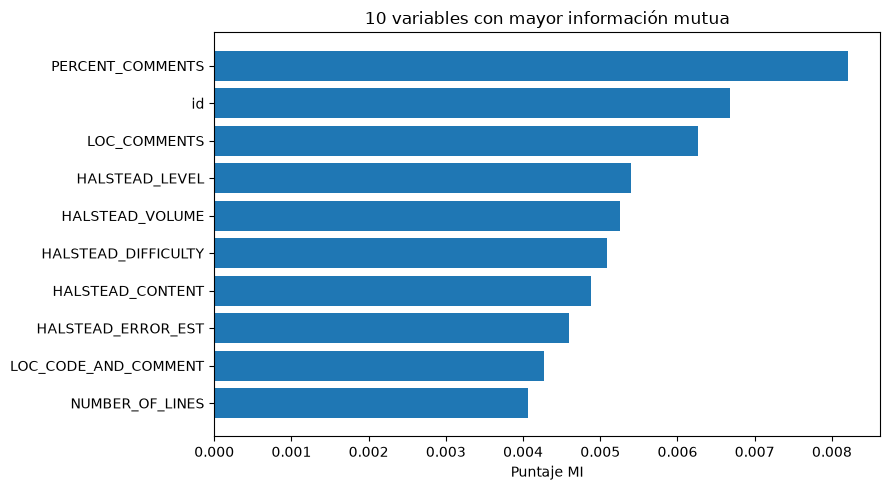

In [67]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_mi["Variable"].iloc[::-1], top_mi["Información mutua"].iloc[::-1])
ax.set_xlabel("Puntaje MI")
ax.set_title("10 variables con mayor información mutua")
plt.tight_layout()
plt.show()

### Método 2: RFE — Recursive Feature Elimination

Entrenamos repetidamente una regresión logística y retiramos la característica con menor importancia en cada iteración. `ranking=1` significa que sobrevivió. `n_features_to_select=K` se fija **antes** de observar resultados.

In [68]:
estimador_rfe = LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEMILLA)
modelo_rfe = RFE(estimator=estimador_rfe, n_features_to_select=min(K, len(columnas)), step=1)

In [69]:
inicio = time.perf_counter()
modelo_rfe.fit(X_ent_std, y_ent)
tiempos["RFE"] = time.perf_counter() - inicio

In [70]:
ranking_rfe = pd.DataFrame({"Variable": columnas, "Ranking RFE": modelo_rfe.ranking_, "Seleccionada": modelo_rfe.support_}).sort_values(["Ranking RFE", "Variable"]).reset_index(drop=True)
display(ranking_rfe)

,Variable,Ranking RFE,Seleccionada
0,DECISION_COUNT,1,True
1,HALSTEAD_CONTENT,1,True
2,HALSTEAD_LENGTH,1,True
3,HALSTEAD_PROG_TIME,1,True
4,LOC_TOTAL,1,True
5,MODIFIED_CONDITION_COUNT,1,True
6,NODE_COUNT,1,True
7,NORMALIZED_CYLOMATIC_COMPLEXITY,1,True
8,NUM_OPERATORS,1,True
9,NUM_UNIQUE_OPERANDS,1,True


In [71]:
seleccion["RFE"] = [columnas[i] for i in np.flatnonzero(modelo_rfe.support_)]
print("Variables supervivientes:", seleccion["RFE"])
print("Número:", len(seleccion["RFE"]), "| Tiempo (s):", round(tiempos["RFE"], 4))

Variables supervivientes: ['DECISION_COUNT', 'HALSTEAD_CONTENT', 'HALSTEAD_LENGTH', 'HALSTEAD_PROG_TIME', 'MODIFIED_CONDITION_COUNT', 'NODE_COUNT', 'NORMALIZED_CYLOMATIC_COMPLEXITY', 'NUM_OPERATORS', 'NUM_UNIQUE_OPERANDS', 'LOC_TOTAL']
Número: 10 | Tiempo (s): 0.2143


### Método 3: LASSO / regularización L1

Para **clasificación binaria**, usamos regresión logística penalizada con L1 (a menudo denominada informalmente LASSO logístico). **No** utilizamos la regresión `Lasso` clásica porque ésta predice una cantidad continua, no probabilidades de clase. Los coeficientes iguales a cero representan variables eliminadas. La fuerza `C_L1` queda documentada.

In [72]:
modelo_l1 = LogisticRegression(penalty="l1", solver="liblinear", C=C_L1, max_iter=4000, class_weight="balanced", random_state=SEMILLA)

In [73]:
inicio = time.perf_counter()
modelo_l1.fit(X_ent_std, y_ent)
tiempos["LASSO (L1)"] = time.perf_counter() - inicio

/Users/uriel/Documents/ErrorPrediction/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/uriel/Documents/ErrorPrediction/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [74]:
coeficientes_l1 = pd.DataFrame({"Variable": columnas, "Coeficiente": modelo_l1.coef_.ravel()})
coeficientes_l1["Conservada"] = coeficientes_l1["Coeficiente"].abs() > 1e-8
display(coeficientes_l1.sort_values("Coeficiente", key=lambda s: s.abs(), ascending=False))

,Variable,Coeficiente,Conservada
17,HALSTEAD_CONTENT,-14.011827,True
32,NUM_UNIQUE_OPERANDS,13.175046,True
20,HALSTEAD_ERROR_EST,-11.843360,True
31,NUM_OPERATORS,10.802597,True
36,LOC_TOTAL,-7.681598,True
29,NORMALIZED_CYLOMATIC_COMPLEXITY,-5.293512,True
34,NUMBER_OF_LINES,4.386513,True
21,HALSTEAD_LENGTH,4.065542,True
26,MODIFIED_CONDITION_COUNT,3.225021,True
12,EDGE_COUNT,-2.865172,True


In [75]:
seleccion["LASSO (L1)"] = coeficientes_l1.loc[coeficientes_l1["Conservada"], "Variable"].tolist()
print("Variables conservadas:", seleccion["LASSO (L1)"])
print("Número:", len(seleccion["LASSO (L1)"]), "| Tiempo (s):", round(tiempos["LASSO (L1)"], 4))

Variables conservadas: ['id', 'LOC_COMMENTS', 'CYCLOMATIC_COMPLEXITY', 'CYCLOMATIC_DENSITY', 'DECISION_COUNT', 'DECISION_DENSITY', 'DESIGN_COMPLEXITY', 'DESIGN_DENSITY', 'EDGE_COUNT', 'ESSENTIAL_COMPLEXITY', 'ESSENTIAL_DENSITY', 'LOC_EXECUTABLE', 'PARAMETER_COUNT', 'HALSTEAD_CONTENT', 'HALSTEAD_DIFFICULTY', 'HALSTEAD_EFFORT', 'HALSTEAD_ERROR_EST', 'HALSTEAD_LENGTH', 'HALSTEAD_LEVEL', 'HALSTEAD_PROG_TIME', 'MAINTENANCE_SEVERITY', 'MODIFIED_CONDITION_COUNT', 'NORMALIZED_CYLOMATIC_COMPLEXITY', 'NUM_OPERATORS', 'NUM_UNIQUE_OPERANDS', 'NUM_UNIQUE_OPERATORS', 'NUMBER_OF_LINES', 'PERCENT_COMMENTS', 'LOC_TOTAL']
Número: 29 | Tiempo (s): 7.0192


In [76]:
display(coeficientes_l1.loc[~coeficientes_l1["Conservada"], ["Variable", "Coeficiente"]].rename(columns={"Coeficiente": "Coeficiente cero"}))

,Variable,Coeficiente cero
1,BRANCH_COUNT,0.0
2,CALL_PAIRS,0.0
3,LOC_CODE_AND_COMMENT,0.0
5,CONDITION_COUNT,0.0
24,HALSTEAD_VOLUME,0.0
27,MULTIPLE_CONDITION_COUNT,0.0
28,NODE_COUNT,0.0
30,NUM_OPERANDS,0.0


In [77]:
if not seleccion["LASSO (L1)"]:
    raise ValueError("L1 anuló todos los coeficientes; ajusta C_L1, declara el cambio y vuelve a ejecutar desde el modelo L1.")

### Método 4: Algoritmo Genético (PyGAD)

Cada **cromosoma binario** tiene una posición por variable: `1` conservar y `0` descartar. Su fitness combina el **F1 medio de validación cruzada estratificada solo en entrenamiento** y una penalización pequeña por tamaño: `fitness = F1_CV − λ × (n_elegidas/p)`. La penalización promueve modelos compactos, por lo que el fitness **no es el F1 puro**; ambos se reportan por separado. El cromosoma vacío recibe un valor penalizado. La validación interna evita usar prueba en la búsqueda; puede ser costosa.

In [78]:
cv_interna = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
print("Folds de validación interna:", cv_interna.n_splits)

Folds de validación interna: 3


In [79]:
def puntuacion_subconjunto(mascara):
    indices = np.flatnonzero(np.asarray(mascara, dtype=int))
    if len(indices) == 0:
        return -1.0, 0.0
    estimador = LogisticRegression(max_iter=2500, class_weight="balanced", random_state=SEMILLA)
    f1_cv = cross_val_score(estimador, X_ent_std[:, indices], y_ent, cv=cv_interna, scoring="f1", n_jobs=1).mean()
    fitness = float(f1_cv - PENALIZACION_TAMANO * len(indices) / X_ent_std.shape[1])
    return fitness, float(f1_cv)

In [80]:
def funcion_fitness(ga_instance, solution, solution_idx):
    fitness, _ = puntuacion_subconjunto(solution)
    return fitness

In [81]:
ag = pygad.GA(num_generations=GENERACIONES_AG,
              num_parents_mating=4,
              sol_per_pop=POBLACION_AG,
              num_genes=len(columnas),
              gene_space=[0, 1],
              gene_type=int,
              fitness_func=funcion_fitness,
              parent_selection_type="tournament",
              K_tournament=3,
              crossover_type="single_point",
              mutation_type="random",
              mutation_probability=0.10,
              keep_elitism=1,
              random_seed=SEMILLA,
              suppress_warnings=True)

In [82]:
inicio = time.perf_counter()
ag.run()
tiempos["Algoritmo Genético"] = time.perf_counter() - inicio

In [83]:
mejor_cromosoma, fitness_ag, indice_ag = ag.best_solution()
mejor_cromosoma = np.asarray(mejor_cromosoma, dtype=int)
print("Mejor cromosoma (0/1):", mejor_cromosoma.tolist())
print("Fitness penalizado:", round(float(fitness_ag), 5))

Mejor cromosoma (0/1): [0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0]
Fitness penalizado: 0.06905


In [84]:
fitness_verificado, f1_cv_ag = puntuacion_subconjunto(mejor_cromosoma)
print("F1 interno del mejor cromosoma:", round(f1_cv_ag, 5))
print("Fitness recalculado:", round(fitness_verificado, 5))

F1 interno del mejor cromosoma: 0.07878
Fitness recalculado: 0.06905


In [85]:
seleccion["Algoritmo Genético"] = [columnas[i] for i in np.flatnonzero(mejor_cromosoma)]
print("Variables elegidas:", seleccion["Algoritmo Genético"])
print("Número:", len(seleccion["Algoritmo Genético"]))
print("Generaciones realizadas:", ag.generations_completed)
print("Tiempo (s):", round(tiempos["Algoritmo Genético"], 4))

Variables elegidas: ['LOC_CODE_AND_COMMENT', 'CYCLOMATIC_DENSITY', 'DECISION_COUNT', 'DESIGN_COMPLEXITY', 'DESIGN_DENSITY', 'LOC_EXECUTABLE', 'PARAMETER_COUNT', 'HALSTEAD_CONTENT', 'HALSTEAD_DIFFICULTY', 'HALSTEAD_EFFORT', 'HALSTEAD_ERROR_EST', 'HALSTEAD_LENGTH', 'HALSTEAD_LEVEL', 'MODIFIED_CONDITION_COUNT', 'NORMALIZED_CYLOMATIC_COMPLEXITY', 'NUM_OPERATORS', 'NUM_UNIQUE_OPERANDS', 'PERCENT_COMMENTS']
Número: 18
Generaciones realizadas: 12
Tiempo (s): 2.7479


In [86]:
display(pd.DataFrame({"Variable": columnas, "Gen": mejor_cromosoma, "Incluida": mejor_cromosoma.astype(bool)}))

,Variable,Gen,Incluida
0,id,0,False
1,BRANCH_COUNT,0,False
2,CALL_PAIRS,0,False
3,LOC_CODE_AND_COMMENT,1,True
4,LOC_COMMENTS,0,False
5,CONDITION_COUNT,0,False
6,CYCLOMATIC_COMPLEXITY,0,False
7,CYCLOMATIC_DENSITY,1,True
8,DECISION_COUNT,1,True
9,DECISION_DENSITY,0,False


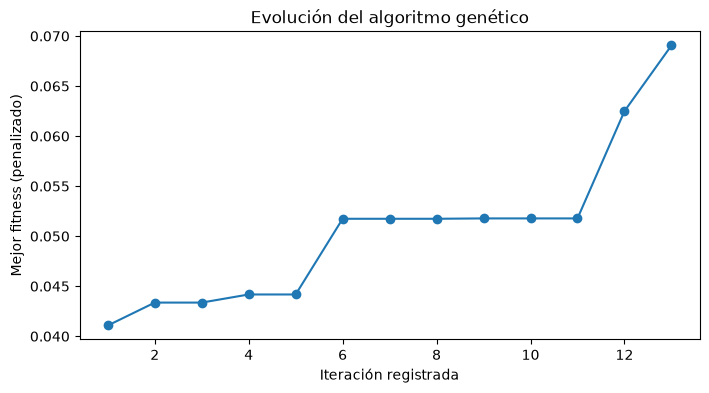

In [87]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(ag.best_solutions_fitness) + 1), ag.best_solutions_fitness, marker="o")
ax.set_xlabel("Iteración registrada")
ax.set_ylabel("Mejor fitness (penalizado)")
ax.set_title("Evolución del algoritmo genético")
plt.show()

## Clasificación con regresión logística

Todos los métodos entregan columnas del mismo PC2. Se ajusta un **nuevo clasificador equivalente** sobre entrenamiento y se evalúa una única vez sobre prueba. Incluimos también un **modelo base con todas las características** para verificar el impacto de reducir dimensionalidad. El mismo modelo, partición y tratamiento de clases se aplican en cada caso.

**Definiciones:** Accuracy = `(VP+VN)/N`; Precision = `VP/(VP+FP)`; Recall = `VP/(VP+FN)`; F1 = `2·Precision·Recall/(Precision+Recall)`. Se toma como clase positiva «defectuoso = 1».

In [88]:
seleccion["Todas las variables (base)"] = columnas.copy()
print("Modelo base:", len(columnas), "variables")

Modelo base: 37 variables


In [90]:
resultados = []
predicciones = {}
modelos_finales = {}

Cada iteración del siguiente `for` conserva **todas sus operaciones en la misma celda**: construye las matrices, entrena, predice y acumula una fila. No se dividen bloques entre celdas.

In [91]:
for nombre, variables in seleccion.items():
    if len(variables) == 0:
        raise ValueError(f"El método {nombre} no seleccionó ninguna variable.")
    indices = [columnas.index(v) for v in variables]
    modelo = LogisticRegression(max_iter=4000, class_weight="balanced", random_state=SEMILLA)
    inicio_modelo = time.perf_counter()
    modelo.fit(X_ent_std[:, indices], y_ent)
    tiempo_entrenamiento = time.perf_counter() - inicio_modelo
    pred = modelo.predict(X_prueba_std[:, indices])
    predicciones[nombre] = pred
    modelos_finales[nombre] = modelo
    resultados.append({"Método": nombre, "Variables": len(variables),
                       "Accuracy": accuracy_score(y_prueba, pred),
                       "Precision": precision_score(y_prueba, pred, zero_division=0),
                       "Recall": recall_score(y_prueba, pred, zero_division=0),
                       "F1": f1_score(y_prueba, pred, zero_division=0),
                       "Tiempo entrenamiento (s)": tiempo_entrenamiento})

In [92]:
tabla_desempeno = pd.DataFrame(resultados).sort_values(["F1", "Recall"], ascending=False).reset_index(drop=True)
display(tabla_desempeno.round(4))

,Método,Variables,Accuracy,Precision,Recall,F1,Tiempo entrenamiento (s)
0,Información Mutua,10,0.8485,0.0195,0.7143,0.0379,0.0080
1,RFE,10,0.9231,0.0000,0.0000,0.0000,0.0074
2,LASSO (L1),29,0.9213,0.0000,0.0000,0.0000,0.0100
3,Algoritmo Genético,18,0.9165,0.0000,0.0000,0.0000,0.0079
4,Todas las variables (base),37,0.9225,0.0000,0.0000,0.0000,0.0100


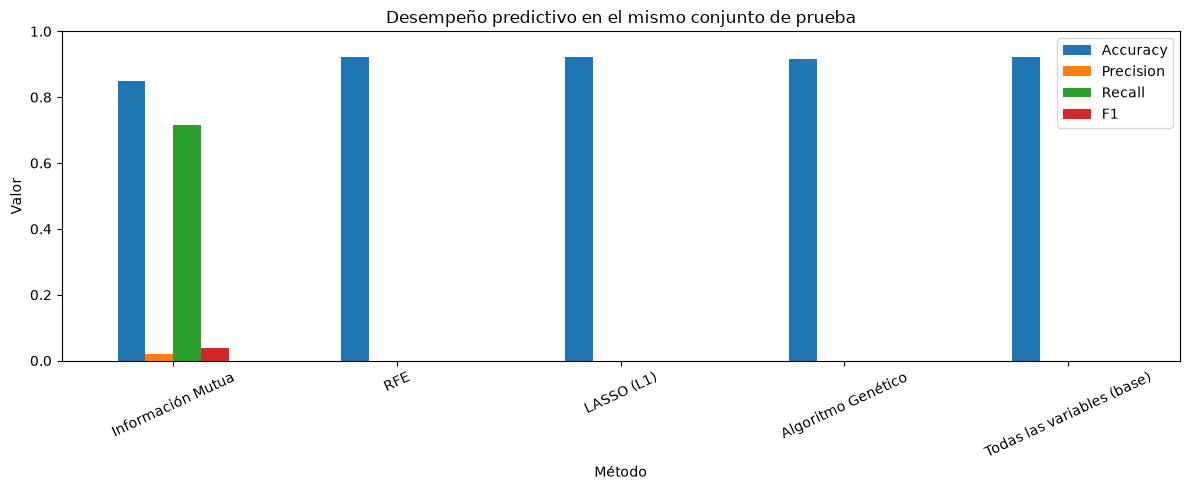

In [93]:
tabla_desempeno.set_index("Método")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(12, 5), ylim=(0, 1), rot=25)
plt.title("Desempeño predictivo en el mismo conjunto de prueba")
plt.ylabel("Valor")
plt.tight_layout()
plt.show()

La matriz de confusión identifica falsos negativos: módulos defectuosos que el modelo clasificó como no defectuosos. En aplicaciones de calidad, estos casos pueden importar más que la Accuracy global.

In [94]:
for nombre, pred in predicciones.items():
    print("\n", nombre)
    print("Matriz [VN, FP; FN, VP]:")
    display(pd.DataFrame(confusion_matrix(y_prueba, pred, labels=[0, 1]), index=["Real 0", "Real 1"], columns=["Predicho 0", "Predicho 1"]))
    print(classification_report(y_prueba, pred, labels=[0, 1], zero_division=0))


 Información Mutua
Matriz [VN, FP; FN, VP]:


,Predicho 0,Predicho 1
Real 0,1418,252
Real 1,2,5


              precision    recall  f1-score   support

           0       1.00      0.85      0.92      1670
           1       0.02      0.71      0.04         7

    accuracy                           0.85      1677
   macro avg       0.51      0.78      0.48      1677
weighted avg       0.99      0.85      0.91      1677


 RFE
Matriz [VN, FP; FN, VP]:


,Predicho 0,Predicho 1
Real 0,1548,122
Real 1,7,0


              precision    recall  f1-score   support

           0       1.00      0.93      0.96      1670
           1       0.00      0.00      0.00         7

    accuracy                           0.92      1677
   macro avg       0.50      0.46      0.48      1677
weighted avg       0.99      0.92      0.96      1677


 LASSO (L1)
Matriz [VN, FP; FN, VP]:


...

              precision    recall  f1-score   support

           0       1.00      0.93      0.96      1670
           1       0.00      0.00      0.00         7

    accuracy                           0.92      1677
   macro avg       0.50      0.46      0.48      1677
weighted avg       0.99      0.92      0.96      1677


 Algoritmo Genético
Matriz [VN, FP; FN, VP]:


,Predicho 0,Predicho 1
Real 0,1537,133
Real 1,7,0


              precision    recall  f1-score   support

           0       1.00      0.92      0.96      1670
           1       0.00      0.00      0.00         7

    accuracy                           0.92      1677
   macro avg       0.50      0.46      0.48      1677
weighted avg       0.99      0.92      0.95      1677


 Todas las variables (base)
Matriz [VN, FP; FN, VP]:


,Predicho 0,Predicho 1
Real 0,1547,123
Real 1,7,0


              precision    recall  f1-score   support

           0       1.00      0.93      0.96      1670
           1       0.00      0.00      0.00         7

    accuracy                           0.92      1677
   macro avg       0.50      0.46      0.48      1677
weighted avg       0.99      0.92      0.96      1677



## Comparación experimental: seleccionadas, comunes y descartadas

Consideramos únicamente los cuatro métodos de selección (no el modelo base). Se comparan subconjuntos exactos, recurrencias y exclusividades. Para detectar redundancia adicional calculamos correlación **solo en entrenamiento**, sin afirmar que correlación implique causalidad.

In [95]:
metodos = ["Información Mutua", "RFE", "LASSO (L1)", "Algoritmo Genético"]
tabla_presencia = pd.DataFrame({m: [v in seleccion[m] for v in columnas] for m in metodos}, index=columnas)
tabla_presencia["Frecuencia"] = tabla_presencia[metodos].sum(axis=1)
display(tabla_presencia.sort_values("Frecuencia", ascending=False))

,Información Mutua,RFE,LASSO (L1),Algoritmo Genético,Frecuencia
HALSTEAD_CONTENT,True,True,True,True,4
HALSTEAD_DIFFICULTY,True,False,True,True,3
PERCENT_COMMENTS,True,False,True,True,3
NUM_UNIQUE_OPERANDS,False,True,True,True,3
NUM_OPERATORS,False,True,True,True,3
NORMALIZED_CYLOMATIC_COMPLEXITY,False,True,True,True,3
MODIFIED_CONDITION_COUNT,False,True,True,True,3
DECISION_COUNT,False,True,True,True,3
HALSTEAD_LEVEL,True,False,True,True,3
HALSTEAD_LENGTH,False,True,True,True,3


In [96]:
comunes = tabla_presencia.index[tabla_presencia["Frecuencia"] == len(metodos)].tolist()
recurrentes = tabla_presencia.index[tabla_presencia["Frecuencia"] >= 2].tolist()
exclusivas = tabla_presencia.index[tabla_presencia["Frecuencia"] == 1].tolist()
descartadas = tabla_presencia.index[tabla_presencia["Frecuencia"] == 0].tolist()
print("Comunes a los 4:", comunes)
print("Recurrentes (≥2):", recurrentes)
print("Exclusivas de un método:", exclusivas)
print("Descartadas por todos:", descartadas)

Comunes a los 4: ['HALSTEAD_CONTENT']
Recurrentes (≥2): ['id', 'LOC_CODE_AND_COMMENT', 'LOC_COMMENTS', 'CYCLOMATIC_DENSITY', 'DECISION_COUNT', 'DESIGN_COMPLEXITY', 'DESIGN_DENSITY', 'LOC_EXECUTABLE', 'PARAMETER_COUNT', 'HALSTEAD_CONTENT', 'HALSTEAD_DIFFICULTY', 'HALSTEAD_EFFORT', 'HALSTEAD_ERROR_EST', 'HALSTEAD_LENGTH', 'HALSTEAD_LEVEL', 'HALSTEAD_PROG_TIME', 'MODIFIED_CONDITION_COUNT', 'NORMALIZED_CYLOMATIC_COMPLEXITY', 'NUM_OPERATORS', 'NUM_UNIQUE_OPERANDS', 'NUMBER_OF_LINES', 'PERCENT_COMMENTS', 'LOC_TOTAL']
Exclusivas de un método: ['CYCLOMATIC_COMPLEXITY', 'DECISION_DENSITY', 'EDGE_COUNT', 'ESSENTIAL_COMPLEXITY', 'ESSENTIAL_DENSITY', 'HALSTEAD_VOLUME', 'MAINTENANCE_SEVERITY', 'NODE_COUNT', 'NUM_UNIQUE_OPERATORS']
Descartadas por todos: ['BRANCH_COUNT', 'CALL_PAIRS', 'CONDITION_COUNT', 'MULTIPLE_CONDITION_COUNT', 'NUM_OPERANDS']


In [97]:
for metodo in metodos:
    solo_este = tabla_presencia.index[tabla_presencia[metodo] & (tabla_presencia["Frecuencia"] == 1)].tolist()
    print(metodo, "— Exclusivas:", solo_este)

Información Mutua — Exclusivas: ['HALSTEAD_VOLUME']
RFE — Exclusivas: ['NODE_COUNT']
LASSO (L1) — Exclusivas: ['CYCLOMATIC_COMPLEXITY', 'DECISION_DENSITY', 'EDGE_COUNT', 'ESSENTIAL_COMPLEXITY', 'ESSENTIAL_DENSITY', 'MAINTENANCE_SEVERITY', 'NUM_UNIQUE_OPERATORS']
Algoritmo Genético — Exclusivas: []


In [98]:
tabla_costo = pd.DataFrame({"Método": metodos, "Tiempo de selección (s)": [tiempos[m] for m in metodos], "Variables conservadas": [len(seleccion[m]) for m in metodos], "Porcentaje conservado": [100 * len(seleccion[m]) / len(columnas) for m in metodos]})
display(tabla_costo.round(4))

,Método,Tiempo de selección (s),Variables conservadas,Porcentaje conservado
0,Información Mutua,0.1702,10,27.0270
1,RFE,0.2143,10,27.0270
2,LASSO (L1),7.0192,29,78.3784
3,Algoritmo Genético,2.7479,18,48.6486


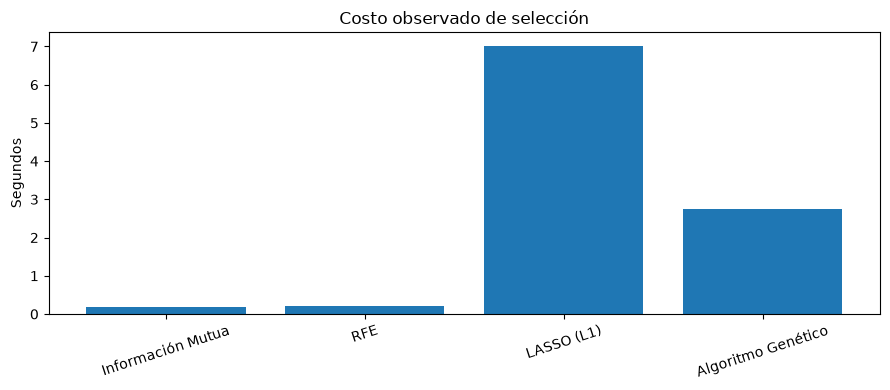

In [99]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(tabla_costo["Método"], tabla_costo["Tiempo de selección (s)"])
ax.set_ylabel("Segundos")
ax.set_title("Costo observado de selección")
ax.tick_params(axis="x", labelrotation=18)
plt.tight_layout()
plt.show()

**Complejidad cualitativa:** MI puntúa cada variable de manera independiente; RFE vuelve a entrenar el modelo varias veces; L1 resuelve una optimización regularizada; el AG evalúa repetidamente poblaciones de subconjuntos y validaciones cruzadas. Los tiempos observados son propios del equipo y los hiperparámetros utilizados; no son órdenes universales de complejidad.

In [100]:
correlacion_abs = pd.DataFrame(X_ent_imp, columns=columnas).corr().abs()
triangulo = correlacion_abs.where(np.triu(np.ones(correlacion_abs.shape), k=1).astype(bool))
pares_correlacionados = triangulo.stack().reset_index()
pares_correlacionados.columns = ["Variable 1", "Variable 2", "Correlación absoluta"]
pares_correlacionados = pares_correlacionados.sort_values("Correlación absoluta", ascending=False)
display(pares_correlacionados.head(15))

,Variable 1,Variable 2,Correlación absoluta
726,HALSTEAD_EFFORT,HALSTEAD_PROG_TIME,1.000000
212,CONDITION_COUNT,MULTIPLE_CONDITION_COUNT,0.999959
764,HALSTEAD_ERROR_EST,HALSTEAD_VOLUME,0.999768
147,LOC_CODE_AND_COMMENT,LOC_TOTAL,0.997601
808,HALSTEAD_LENGTH,NUM_OPERATORS,0.996196
989,MODIFIED_CONDITION_COUNT,MULTIPLE_CONDITION_COUNT,0.995174
211,CONDITION_COUNT,MODIFIED_CONDITION_COUNT,0.995117
472,EDGE_COUNT,NODE_COUNT,0.994970
43,BRANCH_COUNT,CYCLOMATIC_COMPLEXITY,0.993686
193,CONDITION_COUNT,DECISION_COUNT,0.993161


In [101]:
umbral_redundancia = 0.90
pares_muy_correlacionados = pares_correlacionados[pares_correlacionados["Correlación absoluta"] >= umbral_redundancia]
print("Pares con |r| >=", umbral_redundancia, ":", len(pares_muy_correlacionados))
display(pares_muy_correlacionados)

Pares con |r| >= 0.9 : 54


,Variable 1,Variable 2,Correlación absoluta
726,HALSTEAD_EFFORT,HALSTEAD_PROG_TIME,1.000000
212,CONDITION_COUNT,MULTIPLE_CONDITION_COUNT,0.999959
764,HALSTEAD_ERROR_EST,HALSTEAD_VOLUME,0.999768
147,LOC_CODE_AND_COMMENT,LOC_TOTAL,0.997601
808,HALSTEAD_LENGTH,NUM_OPERATORS,0.996196
989,MODIFIED_CONDITION_COUNT,MULTIPLE_CONDITION_COUNT,0.995174
211,CONDITION_COUNT,MODIFIED_CONDITION_COUNT,0.995117
472,EDGE_COUNT,NODE_COUNT,0.994970
43,BRANCH_COUNT,CYCLOMATIC_COMPLEXITY,0.993686
193,CONDITION_COUNT,DECISION_COUNT,0.993161


**Interpretación cautelosa:** una correlación alta es evidencia de posible redundancia lineal, pero no prueba que las dos métricas sean intercambiables en todas las condiciones. La ausencia de correlación lineal tampoco descarta relaciones no lineales.

## Maldición de la dimensionalidad y búsqueda exhaustiva

Con `p` variables binarias, el número de subconjuntos posibles es `2^p` (incluyendo el conjunto vacío). Con 36 variables, la consigna plantea un caso hipotético; mostramos **también** el número real de columnas de la versión de PC2 utilizada.

In [102]:
print("Si p = 36:", f"{2**36:,}", "subconjuntos (incluido el vacío)")
print("Para PC2 procesado, p =", len(columnas), ":", f"{2**len(columnas):,}", "subconjuntos (incluido el vacío)")

Si p = 36: 68,719,476,736 subconjuntos (incluido el vacío)
Para PC2 procesado, p = 37 : 137,438,953,472 subconjuntos (incluido el vacío)


In [103]:
segundos_por_subconjunto = 0.01  # Solo escenario ilustrativo: NO medido.
horas_hipoteticas_36 = (2**36) * segundos_por_subconjunto / 3600
print("Escenario hipotético a 0.01 s/subconjunto (36 variables):", f"{horas_hipoteticas_36:,.1f}", "horas")

Escenario hipotético a 0.01 s/subconjunto (36 variables): 190,887.4 horas


## Cuestionario de análisis crítico

El conjunto PC2 contiene **5,589 módulos**, con **5,566 no defectuosos (99.588 %) y 23 defectuosos (0.412 %)**. De 41 columnas candidatas, el notebook elimina cuatro constantes y compara **37 características**, incluyendo `id`. La división de entrenamiento y prueba es de **3,912** y **1,677** registros; en prueba hay **7 defectuosos y 1,670 no defectuosos**. La extremadamente baja prevalencia de defectos exige privilegiar Recall, Precision, F1 y los falsos negativos, no solo Accuracy.

| Método | Variables | Accuracy | Precision | Recall | F1 | Selección (s) |
|---|---:|---:|---:|---:|---:|---:|
| Información Mutua | 10 | 0.8485 | 0.0195 | 0.7143 | 0.0379 | 0.1702 |
| RFE | 10 | **0.9231** | 0.0000 | 0.0000 | 0.0000 | 0.2143 |
| LASSO (L1) | 29 | 0.9213 | 0.0000 | 0.0000 | 0.0000 | 7.0192 |
| Algoritmo Genético | 18 | 0.9165 | 0.0000 | 0.0000 | 0.0000 | 2.7479 |
| Todas las variables (base) | 37 | 0.9225 | 0.0000 | 0.0000 | 0.0000 | No se hizo selección |

*Nota:* los tiempos son de selección de características y no incluyen necesariamente todo el costo experimental; las cifras se toman de las salidas guardadas. La evaluación se efectuó con una sola partición de prueba.

## Comparación de métodos

### 1. ¿Todos los métodos seleccionaron las mismas variables?

**No.** Información Mutua seleccionó 10 variables, RFE otras 10, LASSO (L1) 29 y el Algoritmo Genético 18. La intersección de los cuatro subconjuntos contiene únicamente **`HALSTEAD_CONTENT`**. Incluso los métodos con igual tamaño (Información Mutua y RFE) eligieron composiciones distintas. Esto muestra que sus criterios de selección no son equivalentes: Información Mutua estima dependencia individual con la etiqueta, RFE elimina variables mediante un estimador, L1 anula coeficientes según su penalización y el algoritmo genético optimiza combinaciones según una función fitness.

### 2. ¿Qué métricas fueron seleccionadas con mayor frecuencia?

**`HALSTEAD_CONTENT` fue la única seleccionada por los cuatro métodos (4/4)**. Aparecieron en **tres de los cuatro**: `HALSTEAD_DIFFICULTY`, `HALSTEAD_ERROR_EST`, `HALSTEAD_LENGTH`, `HALSTEAD_LEVEL`, `NUM_OPERATORS`, `NUM_UNIQUE_OPERANDS`, `NORMALIZED_CYLOMATIC_COMPLEXITY`, `MODIFIED_CONDITION_COUNT`, `DECISION_COUNT` y `PERCENT_COMMENTS`. La recurrencia de métricas de Halstead apunta a un papel relevante de las propiedades de operadores y operandos en los subconjuntos elegidos, pero **frecuencia de selección no demuestra causalidad ni utilidad predictiva individual**.

### 3. ¿Qué variables generaron desacuerdo entre los métodos?

Hubo desacuerdos notorios. **`HALSTEAD_VOLUME`** fue exclusiva de Información Mutua; **`NODE_COUNT`**, exclusiva de RFE. LASSO incorporó exclusivamente `CYCLOMATIC_COMPLEXITY`, `DECISION_DENSITY`, `EDGE_COUNT`, `ESSENTIAL_COMPLEXITY`, `ESSENTIAL_DENSITY`, `MAINTENANCE_SEVERITY` y `NUM_UNIQUE_OPERATORS`; el Algoritmo Genético no tuvo variables exclusivas. También se observaron discrepancias con `PERCENT_COMMENTS`, `HALSTEAD_DIFFICULTY` y `LOC_TOTAL`, seleccionadas por varios métodos, pero no todos. Esto puede explicarse por criterios de relevancia distintos y por las correlaciones entre métricas: una variable puede ser informativa aisladamente y, sin embargo, aportar poco una vez incluidas otras relacionadas.

### 4. ¿Cuál método produjo el subconjunto más pequeño?

Hubo **empate entre Información Mutua y RFE**, ambos con **10 de 37 variables** (27.03 % de los predictores comparados). No es correcto atribuir el mínimo exclusivamente a Información Mutua. La coincidencia es consecuencia, al menos en parte, de la configuración del notebook, que fija `K = 10` para esos métodos; por tanto, no implica que ambos hayan descubierto por sí solos un tamaño óptimo de diez características.

### 5. ¿Cuál método produjo el subconjunto más grande?

**LASSO (L1)** conservó **29 de 37 variables (78.38 %)** y anuló ocho coeficientes. El Algoritmo Genético conservó 18 (48.65 %); Información Mutua y RFE, diez cada uno (27.03 %). El tamaño de LASSO depende del valor de regularización empleado (`C_L1 = 1.0` en el notebook), de la escala de las variables y de sus correlaciones. Por eso, un LASSO más grande en esta ejecución no demuestra que siempre elimine menos características.

## Desempeño predictivo

### 6. ¿El modelo con mejor Accuracy utilizó el menor número de variables?

**Sí, pero no fue el único modelo con ese tamaño.** RFE alcanzó la mayor **Accuracy = 0.9231** con **10 variables**, empatando en tamaño mínimo con Información Mutua. Sin embargo, existe un matiz decisivo: RFE tuvo **Recall = 0, F1 = 0 y siete falsos negativos**, es decir, **no detectó ninguno de los siete módulos defectuosos** presentes en prueba. Información Mutua obtuvo menor Accuracy (0.8485), pero detectó cinco de los siete (Recall = 0.7143). Así, la mejor Accuracy **no equivale al mejor detector de defectos** en un conjunto tan desbalanceado.

### 7. ¿Cuál fue el mejor método considerando simultáneamente desempeño e interpretabilidad?

**Información Mutua constituye la opción más defendible en esta ejecución si la prioridad es detectar módulos potencialmente defectuosos.** Solo utiliza **10 métricas**, consiguió el único **Recall positivo (0.7143)** y el único **F1 positivo (0.0379)**, mientras RFE, LASSO y el algoritmo genético obtuvieron F1 = 0. Su ranking de puntuaciones también es sencillo de explicar. No obstante, su **Precision = 0.0195** implica que únicamente cinco de las 257 alertas positivas correspondían a módulos realmente defectuosos: produjo **252 falsos positivos**. Por consiguiente, es la mejor alternativa relativa entre las probadas para una primera priorización sensible, **no un modelo listo para uso operativo**. La inclusión de `id` en su top 10 obliga, además, a repetir la evaluación sin el identificador antes de adoptar una conclusión definitiva.

### 8. ¿Las diferencias observadas justifican la utilización de métodos más complejos?

**No en esta configuración y con esta evidencia.** Información Mutua tardó **0.1702 s** y fue el único método que reconoció defectos en el conjunto de prueba. RFE tardó 0.2143 s, el Algoritmo Genético 2.7479 s (aproximadamente **16 veces** el tiempo de Información Mutua) y LASSO 7.0192 s (aproximadamente **41 veces**). Los tres métodos restantes mostraron Recall y F1 iguales a cero. Por tanto, su mayor costo no se tradujo aquí en mejor detección. Esta conclusión se limita a la parametrización y ejecución registradas: cambiar hiperparámetros, umbrales, datos o el procedimiento de validación podría modificar la comparación.

## Maldición de la dimensionalidad

### 9. ¿Por qué el problema de selección de características se vuelve más difícil cuando aumenta el número de variables?

Porque cada característica adicional **duplica** el número de subconjuntos posibles: con `p` variables existen **2^p** combinaciones si se incluye el subconjunto vacío. Además, se incrementan las posibilidades de encontrar relaciones casuales, redundancias y soluciones sobreajustadas, especialmente cuando hay muy pocos casos positivos. En PC2 se trabajó con 37 variables y solamente 23 módulos defectuosos en todo el dataset, una relación que limita la estimación fiable de patrones. También aumentan el tiempo de selección y el esfuerzo de interpretar qué variables aportan información genuina.

### 10. Suponga que PC2 contiene 36 variables. ¿Qué implicaciones tiene esto para el número de subconjuntos posibles que podrían evaluarse mediante búsqueda exhaustiva?

Para **36 variables** existen **2^36 = 68,719,476,736 subconjuntos**, contando el vacío; si se descarta el vacío quedan **68,719,476,735** subconjuntos no vacíos. La búsqueda exhaustiva tendría que examinar decenas de miles de millones de combinaciones. Si se aumentase a 37, la cantidad se duplicaría a **137,438,953,472**, que es precisamente el número informado para las 37 variables consideradas en el experimento.

### 11. ¿Resulta factible evaluar todos los subconjuntos posibles de características?

**No es factible con recursos habituales en un experimento como este.** Solo evaluar los 68,719,476,735 subconjuntos no vacíos de 36 variables demandaría cerca de **21.8 años** si cada evaluación tardase hipotéticamente **0.01 segundos** de manera secuencial y sin sobrecostos. Esa cifra es un **escenario ilustrativo**, no una medición del notebook; una validación cruzada con entrenamiento de modelos puede ser más costosa. Por eso se emplean estrategias de filtrado, eliminación, regularización o búsqueda heurística en lugar de enumerar todas las combinaciones.

### 12. ¿Qué ventajas ofrecen RFE, LASSO y los Algoritmos Genéticos frente a una búsqueda exhaustiva?

**RFE** elimina características progresivamente según un estimador, evitando visitar todos los subconjuntos y proporcionando un ranking. **LASSO (L1)** incorpora la selección al ajuste de un modelo lineal mediante coeficientes que pueden hacerse exactamente cero, por lo que evita una búsqueda combinatoria explícita. **Los Algoritmos Genéticos** exploran distintas combinaciones mediante población, selección, cruce y mutación, sin recorrer todo el espacio, y permiten introducir un criterio fitness que combine predicción y penalización por tamaño. En el notebook, RFE tardó **0.2143 s**, LASSO **7.0192 s** y el algoritmo genético **2.7479 s**; son tiempos finitos y muy inferiores a una búsqueda exhaustiva de miles de millones de candidatos, aunque no garantizan hallar el subconjunto óptimo global.

### 13. ¿Observó evidencia de variables redundantes? ¿Cuáles?

**Sí, como indicio de redundancia lineal.** El análisis de correlaciones del notebook detectó **54 pares con correlación absoluta ≥ 0.90**. Ejemplos especialmente claros son `HALSTEAD_EFFORT`–`HALSTEAD_PROG_TIME` (**|r| = 1.000000**), `HALSTEAD_ERROR_EST`–`HALSTEAD_VOLUME` (**0.999768**), `LOC_CODE_AND_COMMENT`–`LOC_TOTAL` (**0.997601**), `HALSTEAD_LENGTH`–`NUM_OPERATORS` (**0.996196**), `EDGE_COUNT`–`NODE_COUNT` (**0.994970**) y `BRANCH_COUNT`–`CYCLOMATIC_COMPLEXITY` (**0.993686**). Estas relaciones sugieren información parcialmente repetida y pueden explicar por qué distintos selectores retuvieron representantes diferentes. **Correlación elevada no demuestra equivalencia perfecta ni ausencia de valor incremental para la predicción**.

### 14. ¿La eliminación de variables produjo una pérdida importante de desempeño predictivo?

**Depende de la métrica, y no hubo una pérdida universal.** El modelo base con **37 variables** alcanzó **Accuracy = 0.9225**, pero **Recall = 0 y F1 = 0**. RFE redujo el conjunto a diez y aumentó ligeramente la Accuracy a **0.9231**, pero siguió sin reconocer defectos. Información Mutua también utilizó diez y disminuyó la Accuracy a **0.8485** (una reducción de 0.0740), a cambio de elevar el **Recall de 0 a 0.7143 y el F1 de 0 a 0.0379**. LASSO (29) y el genético (18) conservaron Accuracy alrededor de 0.92 sin detectar los siete positivos. Así, eliminar variables **no produjo necesariamente un deterioro de la capacidad relevante de detectar defectos**; la valoración depende del costo de falsos negativos frente a falsos positivos.

### 15. ¿Qué relación observa entre complejidad del modelo, número de variables y capacidad de generalización?

Los resultados muestran que **más variables no implican mejor generalización para la clase defectuosa**. El modelo base con 37, LASSO con 29 y el genético con 18 fallaron en los siete positivos de prueba; RFE con diez también falló, mientras que Información Mutua con diez detectó cinco. Esto indica que **la composición de las características importa tanto o más que su cantidad**. Una selección más reducida puede facilitar interpretación y disminuir dimensiones, pero no garantiza por sí sola mejores predicciones. En rigor, solo se dispone de **una partición** con **siete casos positivos en prueba**; sería necesario evaluar varias particiones estratificadas o realizar validación cruzada apropiada para estimar la estabilidad y generalización del resultado.

### 16. Si el dataset tuviera el doble de variables que PC2, ¿qué método esperaría que escalara mejor y por qué?

**Esperaría que Información Mutua escalara mejor en costo de selección**, ya que puntúa cada variable por separado y evita reentrenamientos iterativos de un clasificador para múltiples subconjuntos. Su tiempo medido aquí fue **0.1702 s**, frente a 0.2143 s de RFE, 2.7479 s del algoritmo genético y 7.0192 s de LASSO. L1 también puede escalar bien porque resuelve una optimización regularizada, mientras que RFE requiere ajustes sucesivos y el algoritmo genético evalúa varias soluciones en múltiples generaciones. **No es una demostración experimental de escalabilidad**, puesto que el notebook no ejecutó la prueba con el doble de variables; es una expectativa basada en cómo funcionan los métodos y podría variar según los datos y su implementación.

### 17. ¿Considera que el mejor desempeño siempre justifica el mayor costo computacional?

**No.** La decisión debe considerar cuál es la métrica importante, cuánto se gana, cuánto cuesta y qué riesgos implica equivocarse. Aquí, el método de **mayor Accuracy (RFE, 0.9231)** no detectó ningún defecto; y el de mayor tiempo (LASSO, **7.0192 s**) tampoco mejoró Recall ni F1. Información Mutua fue el más rápido y el único que detectó cinco defectos, aunque a costa de muchos falsos positivos. En ingeniería de software, un modelo costoso solo se justificaría si su mejora fuese estadísticamente consistente y suficientemente relevante para reducir fallas o costos de revisión.

### 18. Desde una perspectiva profesional, ¿preferiría un modelo ligeramente menos preciso pero más simple, o marginalmente más preciso pero significativamente más complejo?

**Preferiría un modelo más simple cuando su capacidad de identificar defectos sea comparable o superior y su costo de mantenimiento sea menor.** En este experimento priorizaría provisionalmente **Información Mutua**, que utiliza diez características y tarda **0.1702 s**, porque detecta cinco de los siete defectuosos, frente a cero en los demás. Sin embargo, **no lo desplegaría todavía**: su Precision de **1.95 %** y sus 252 falsos positivos representan una carga operativa elevada. Antes de la adopción, excluiría `id`, repetiría la evaluación con particiones adecuadas y estudiaría umbrales, curvas precisión-recall y el costo real de revisar cada alerta. La elección profesional debe optimizar la utilidad operativa, no únicamente una diferencia marginal de Accuracy.


## Discusión crítica, limitaciones y conclusión

Los métodos no optimizan necesariamente el mismo objetivo: MI mide dependencia individual, RFE se guía por el estimador, L1 favorece soluciones dispersas y el AG combina validación interna con penalización del número de métricas. La existencia de clases desbalanceadas exige valorar Recall y F1, no solo Accuracy.

**Amenazas a la validez:** 
- las etiquetas históricas pueden estar incompletas
- PC2 podría no representar software de otros dominios 
- una partición hold-out es sensible a la semilla, más aún con pocos casos positivos
- MI, RFE, L1 y AG dependen de hiperparámetros y presupuesto
- selección y entrenamiento en el mismo conjunto de entrenamiento pueden dar estimaciones optimistas si no se usa validación anidada; (6) los tiempos dependen del hardware. Por ello los resultados describen este experimento y no establecen superioridad universal.

Se compararon 4 métodos sobre 5589 instancias y 37 métricas predictoras. El mayor F1 de prueba entre métodos de selección correspondió a Información Mutua (F1=0.0379, Recall=0.7143, 10 variables). Frente al clasificador con todas las variables, el cambio en F1 fue +0.0379. Estas conclusiones dependen de la partición, la calidad de datos y los hiperparámetros usados.


## Referencias y correspondencia con el material de clase


- Peng, H., Long, F., & Ding, C. (2005). Feature selection based on mutual information: Criteria of max-dependency, max-relevance, and min-redundancy. *IEEE Transactions on Pattern Analysis and Machine Intelligence, 27*(8), 1226–1238. https://doi.org/10.1109/TPAMI.2005.159
- Guyon, I., Weston, J., Barnhill, S., & Vapnik, V. (2002). Gene selection for cancer classification using support vector machines. *Machine Learning, 46*, 389–422. https://doi.org/10.1023/A:1012487302797
- Tibshirani, R. (1996). Regression shrinkage and selection via the Lasso. *Journal of the Royal Statistical Society: Series B, 58*(1), 267–288. https://doi.org/10.1111/j.2517-6161.1996.tb02080.x
- Lessmann, S., Baesens, B., Mues, C., & Pietsch, S. (2008). Benchmarking classification models for software defect prediction: A proposed framework and novel findings. *IEEE Transactions on Software Engineering, 34*(4), 485–496. https://doi.org/10.1109/TSE.2008.35